# Q TRUST
## When Does Error Detection Make a Bell Pair Worth Trusting

This notebook presents the executed Track 3 benchmark. The implementation lives in `src/qtrust`; this notebook reads the generated evidence instead of duplicating the experiment.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT / 'src'))
from qtrust.analysis import analytic_raw_fidelity
from qtrust.circuits import build_resource_circuit

basis = pd.read_csv(ROOT / 'results' / 'basis_results.csv')
summary = pd.read_csv(ROOT / 'results' / 'summary_results.csv')
print(f'Loaded {len(basis)} basis experiments and {len(summary)} aggregated settings.')

Loaded 105 basis experiments and 35 aggregated settings.


## 1 Challenge and Research Question

Track 3 asks for a result with a known answer, an ideal and noisy baseline, an error-handling method, and an honest comparison of improvement with cost. Q TRUST asks where an ancilla parity detector improves target Bell-state fidelity and where detector errors or discarded shots make that protection unattractive.

## 2 Why Z Counts Alone Are Insufficient

The target is $|\Phi^+\rangle=(|00\rangle+|11\rangle)/\sqrt{2}$. A classical mixture can also return only `00` and `11` in the Z basis. We therefore estimate $\langle XX\rangle$, $\langle YY\rangle$, and $\langle ZZ\rangle$, then calculate $F=[1+XX-YY+ZZ]/4$.

## 3 Bell State and Three-Basis Measurement

In [2]:
print(build_resource_circuit('Z', with_detector=False).draw(output='text', fold=-1))
ideal = basis[(basis.strategy == 'raw') & (basis.data_noise_p == 0)].set_index('measurement_basis')
ideal[['correlation', 'correlation_standard_error']]

        ┌───┐     ┌─┐   
data_0: ┤ H ├──■──┤M├───
        └───┘┌─┴─┐└╥┘┌─┐
data_1: ─────┤ X ├─╫─┤M├
             └───┘ ║ └╥┘
bits: 2/═══════════╩══╩═
                   0  1 


,correlation,correlation_standard_error
measurement_basis,,
X,1.0,0.0
Y,-1.0,0.0
Z,1.0,0.0


## 4 Controlled Noise Model

After Bell preparation, an explicit Aer Pauli channel independently flips each data qubit with probability `p`. The exact target fidelity is the probability of zero or two flips: $F_{raw}=(1-p)^2+p^2$.

In [3]:
raw = summary[summary.strategy == 'raw'].copy()
raw['analytic_check'] = raw.data_noise_p.map(analytic_raw_fidelity)
raw[['data_noise_p', 'fidelity', 'fidelity_standard_error', 'analytic_check', 'raw_theory_absolute_error']]

,data_noise_p,fidelity,fidelity_standard_error,analytic_check,raw_theory_absolute_error
28,0.00,1.000000,0.000000,1.0000,0.000000
29,0.01,0.980103,0.001091,0.9802,0.000097
30,0.02,0.956360,0.001596,0.9608,0.004440
31,0.05,0.905334,0.002287,0.9050,0.000334
32,0.10,0.820740,0.002997,0.8200,0.000740
33,0.15,0.747253,0.003395,0.7450,0.002253
34,0.20,0.687195,0.003622,0.6800,0.007195


## 5 Raw Noisy Baseline

The maximum raw-versus-analytic deviation is shown below. It stays within the finite-shot validation tolerance.

Maximum absolute deviation: 0.00719


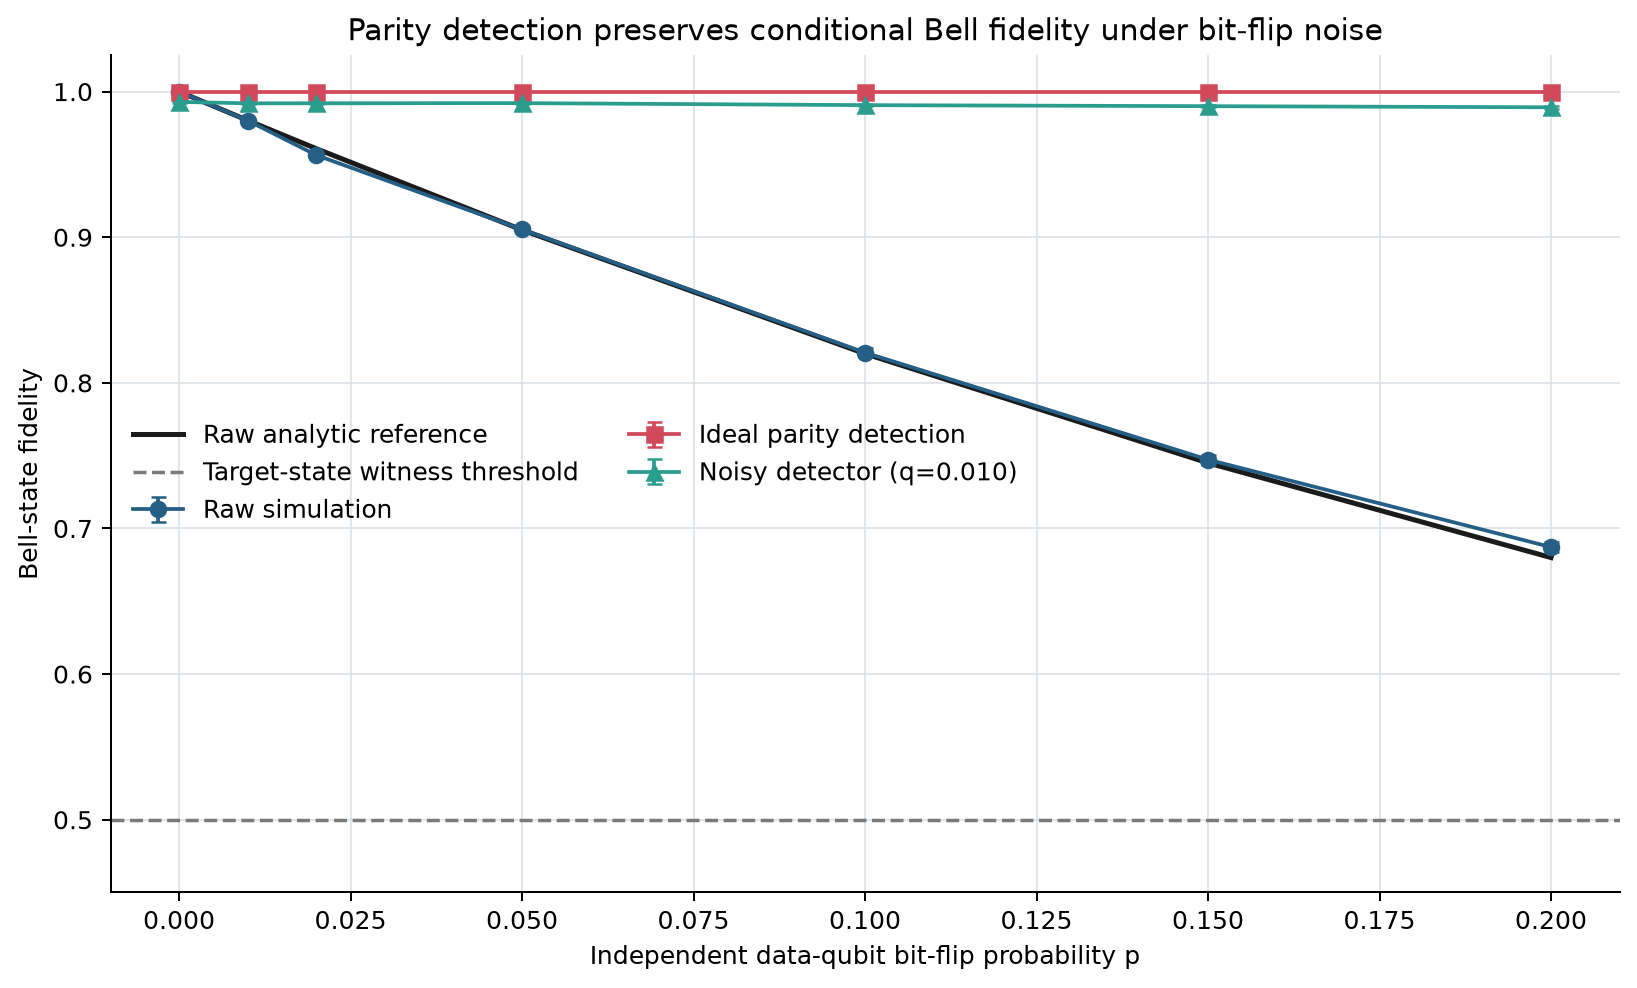

In [4]:
print(f"Maximum absolute deviation: {raw.raw_theory_absolute_error.max():.5f}")
display(Image(filename=str(ROOT / 'figures' / 'fidelity_vs_noise.png'), width=850))

## 6 Parity Detection Circuit

Two CNOTs write data-qubit Z parity onto an ancilla. Qiskit returns detector keys as `s d1 d0`; only `s=0` contributes to each retained correlation.

In [5]:
print(build_resource_circuit('Z', with_detector=True).draw(output='text', fold=-1))

          ┌───┐               ┌─┐      
  data_0: ┤ H ├──■────■───────┤M├──────
          └───┘┌─┴─┐  │       └╥┘┌─┐   
  data_1: ─────┤ X ├──┼────■───╫─┤M├───
               └───┘┌─┴─┐┌─┴─┐ ║ └╥┘┌─┐
syndrome: ──────────┤ X ├┤ X ├─╫──╫─┤M├
                    └───┘└───┘ ║  ║ └╥┘
  bits: 3/═════════════════════╩══╩══╩═
                               0  1  2 


## 7 Fidelity Improvement

In [6]:
selected_p = [0.02, 0.05, 0.10, 0.20]
selected = summary[(summary.data_noise_p.isin(selected_p)) & ((summary.strategy == 'raw') | ((summary.strategy == 'detected') & (summary.detector_noise_q == 0)))]
selected[['strategy', 'data_noise_p', 'fidelity', 'fidelity_standard_error', 'acceptance_rate', 'shot_cost_multiplier']]

,strategy,data_noise_p,fidelity,fidelity_standard_error,acceptance_rate,shot_cost_multiplier
8,detected,0.02,1.000000,0.000000,0.961711,1.039814
12,detected,0.05,1.000000,0.000000,0.899780,1.111382
16,detected,0.10,1.000000,0.000000,0.819173,1.220743
24,detected,0.20,1.000000,0.000000,0.678792,1.473205
30,raw,0.02,0.956360,0.001596,1.000000,1.000000
31,raw,0.05,0.905334,0.002287,1.000000,1.000000
32,raw,0.10,0.820740,0.002997,1.000000,1.000000
34,raw,0.20,0.687195,0.003622,1.000000,1.000000


## 8 Acceptance and Resource Cost

The detector adds one qubit, two CNOTs, and one measurement. Postselection adds a sampling cost that grows as odd-error events become more frequent.

,strategy,num_qubits,max_circuit_depth,max_total_gate_count,max_cx_count,measurement_count
0,detected,3,7,8,3,3
28,raw,2,5,6,1,2


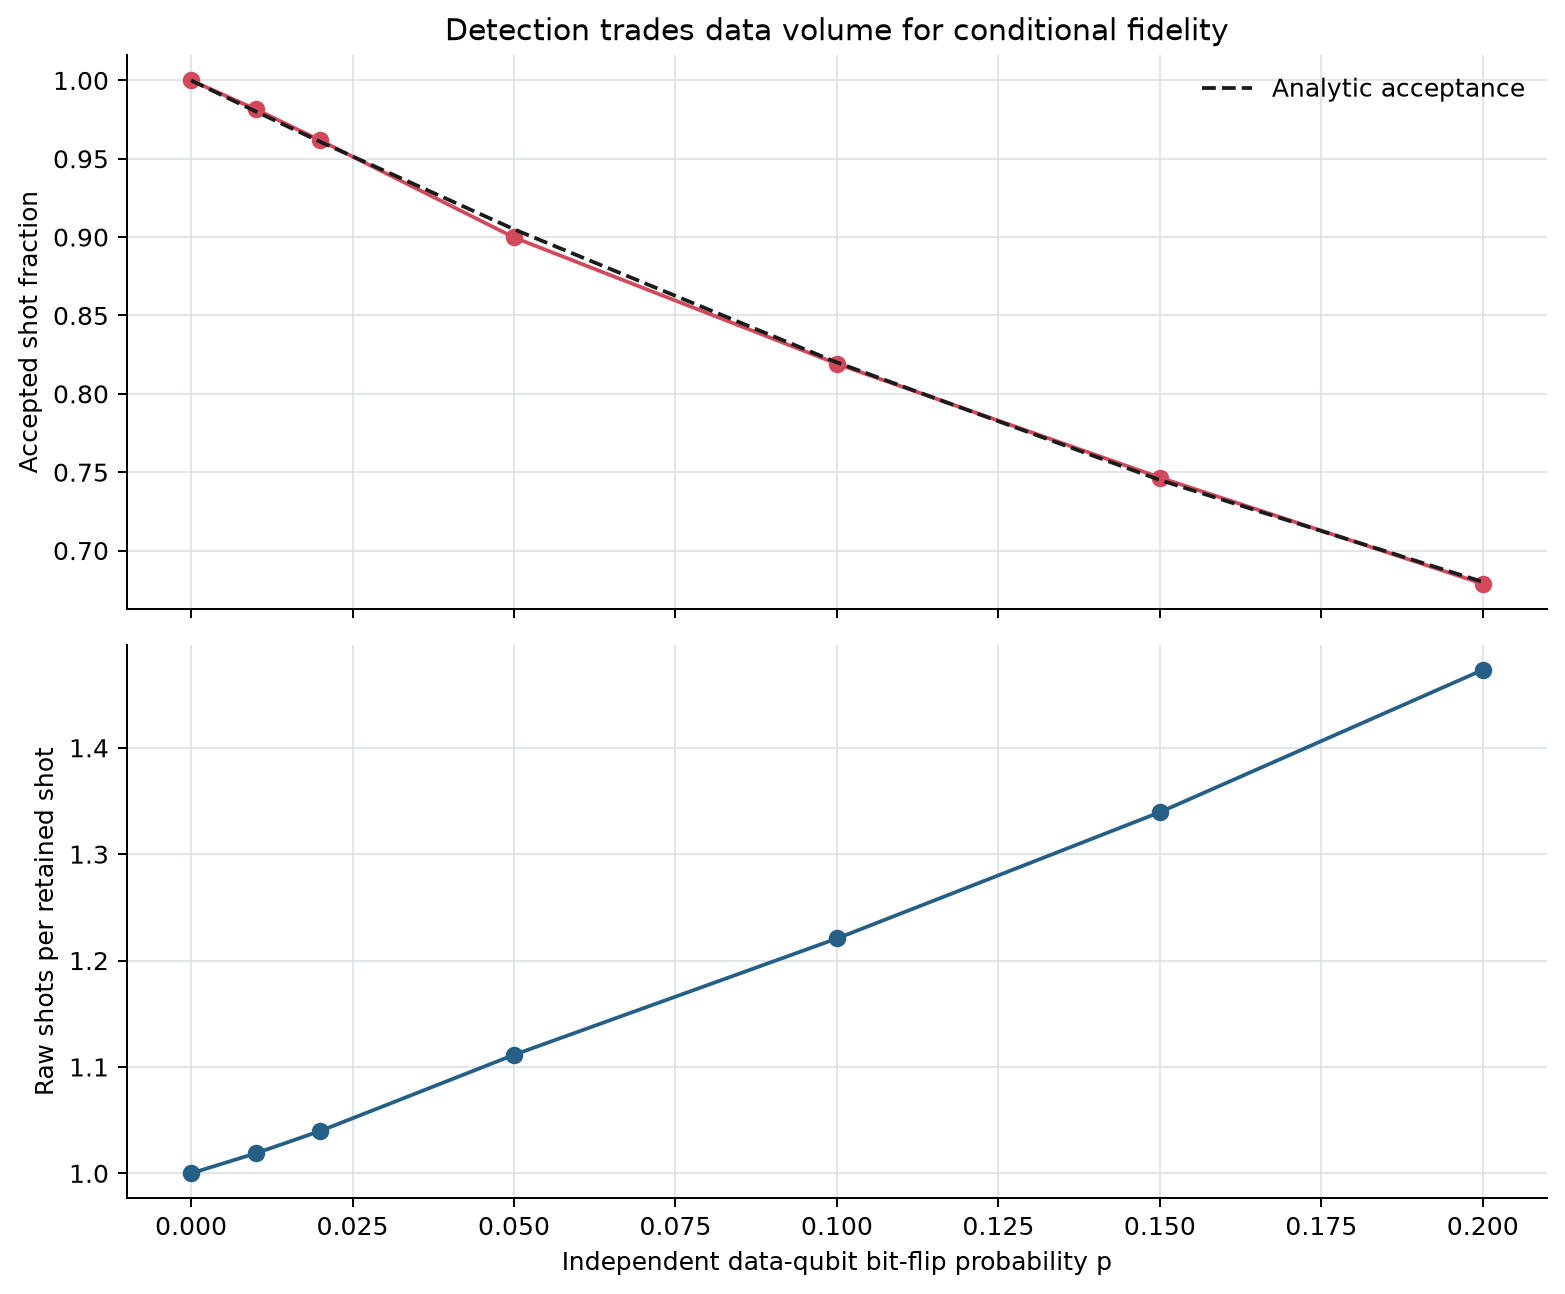

In [7]:
resources = summary[(summary.data_noise_p == 0) & (((summary.strategy == 'raw')) | ((summary.strategy == 'detected') & (summary.detector_noise_q == 0)))]
display(resources[['strategy', 'num_qubits', 'max_circuit_depth', 'max_total_gate_count', 'max_cx_count', 'measurement_count']])
display(Image(filename=str(ROOT / 'figures' / 'detection_cost.png'), width=800))

## 9 Noisy Detector Operating Region

Detector CNOT imperfections are modeled with a two-qubit depolarizing channel. The heatmap reports detected fidelity minus raw fidelity. Negative values mean the detector caused net harm.

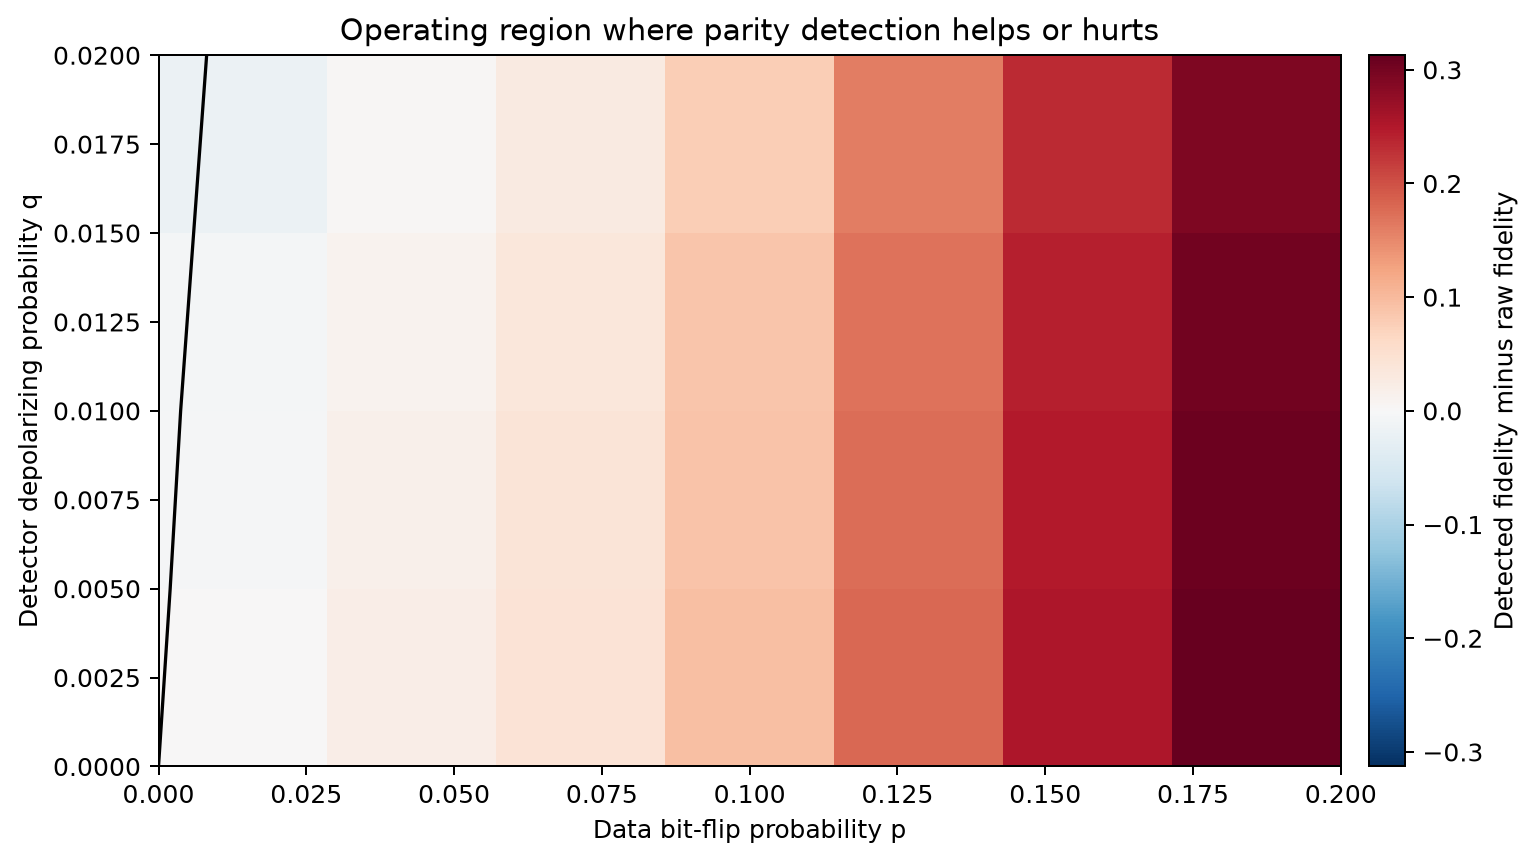

,data_noise_p,fidelity,acceptance_rate,fidelity_improvement
3,0.00,0.982226,0.978678,-0.017774
7,0.01,0.984156,0.963053,0.004053
11,0.02,0.984331,0.942586,0.027971
15,0.05,0.982109,0.887410,0.076775
19,0.10,0.981376,0.806152,0.160637
23,0.15,0.979906,0.740479,0.232652
27,0.20,0.978231,0.672607,0.291036


In [8]:
display(Image(filename=str(ROOT / 'figures' / 'detector_usefulness.png'), width=850))
summary[(summary.strategy == 'detected') & (summary.detector_noise_q == 0.02)][['data_noise_p', 'fidelity', 'acceptance_rate', 'fidelity_improvement']]

## 10 Limitations and Societal Impact

This controlled X-error model is not a complete hardware model. The check misses arbitrary phase errors, added CNOTs can fail, and postselection is detection rather than fault-tolerant correction. Simulator evidence cannot certify a real device. Finite-shot uncertainty remains even when the plug-in error estimate is zero.

The sampling cost also creates an access cost. Groups with larger cloud budgets can discard data and rerun experiments more easily. Responsible reporting should therefore present raw and handled results, acceptance, resources, assumptions, and uncertainty together.

## 11 Reproducibility

From WSL, run:

```bash
cd /mnt/e/QomputeCode
~/miniconda3/bin/conda run -n qtrust python run_experiment.py
~/miniconda3/bin/conda run -n qtrust pytest
```

The CSV files record both seeds, shot counts, noise settings, and transpiled circuit resources.